# Notebook 19 — Kiểm chứng domain-wall ba host và development pilot

**Nhánh A; bước tiếp theo sau checkpoint Notebook18.** Chạy tuần tự trên kernel
nt409-khiem. Notebook này kiểm chứng mô hình, đọc dữ liệu đã khóa, đo controls và
chạy **12 development trials +2 functional smokes**. Có **6 dev probes +2 control probes**.
Tập test không được đưa vào QAOA. Không chọn p từ pilot, không có ngưỡng27/30,24/30.
Kết quả âm vẫn là kết quả hợp lệ. Notebook20 chưa được khởi chạy.

Lần đầu Restart Kernel rồi Run All. Nếu chia phiên, ghi lại đường dẫn được in ở
bước2 và đặt RESUME_DIR trước lần sau. Có thể chọn RUN_INSTANCES theo kích thước;
không đổi số shots, seed, penalty hay cap khi resume. Lượt completed không chạy lại.

## Bước1 — Môi trường và lựa chọn phiên chạy

Giữ nguyên cấu hình được cung cấp. RUN_INSTANCES có thể chỉ chứa a3_dev_n4 cho
phiên4task, rồi bổ sung n5/controls trong cùng folder. RETRY_FAILED mặc định False;
interrupted được recovery, các lỗi khác được giữ để review trước khi thử lại.

In [1]:
from pathlib import Path
import json, sys, platform
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'src/three_host_pilot.py').is_file())
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from src.three_host_benchmark import load_three_host_benchmark, measure_assignment
from src.three_host_pilot import (open_pilot, prepare_models, run_phase, result_rows,
                                  export_pilot, control_rows, verify_pilot)
from src.benchmark_a_campaign import save_json
RESUME_DIR = None  # Ví dụ: 'data/reference_results/phase4k_three_host_pilot/pilot_<id>'
RUN_INSTANCES = ['a3_dev_n4', 'a3_dev_n5', 'a3_one_host', 'a3_infeasible']
RETRY_FAILED = False
CONTEXT = load_three_host_benchmark(ROOT / 'data/benchmarks/nt409_three_host_v2')
print('Runtime:', platform.platform(), platform.python_version())
print('Dataset:', CONTEXT['manifest']['design_sha256'])
print('Cấu hình:', CONTEXT['protocol']['qaoa'])

Runtime: Windows-11-10.0.26200-SP0 3.12.14
Dataset: 0df7ad1f683eb2ae696422d15833e55a73ff5a552e47cf6b33f965bd9fdb8aad
Cấu hình: {'depths': [1, 2, 3], 'optimization_seeds': [190, 191], 'evaluation_seeds': [100190, 100191], 'shots': 1024, 'evaluation_shots': 1024, 'maxiter': 200, 'max_seconds': 2400, 'hamiltonian_scaling': 'max_abs', 'cobyla_rhobeg': 1.0, 'cobyla_tol': 0.0001, 'initial_points_beta_then_gamma': {'1': [0.3, 1.0], '2': [0.3, 0.0, 1.0, 0.0], '3': [0.3, 0.0, 0.0, 1.0, 0.0, 0.0]}}


## Bước2 — Mở pilot mới hoặc tiếp tục pilot cũ

Manifest/hash/source/runtime được khóa để từ chối resume khi thay dữ liệu hoặc code.
Ghi lại RESUME_DIR được in ra. Đủ14 planned trials mới gọi pilot complete; test rows
không có trong planned_runs. Không xóa folder khi cần chia phiên.

In [2]:
FOLDER, CAMPAIGN = open_pilot(ROOT, CONTEXT, RESUME_DIR)
print('RESUME_DIR =', repr(FOLDER.relative_to(ROOT).as_posix()))
print('Planned pilot trials:', len(CAMPAIGN['planned_runs']))
display(pd.DataFrame(CONTEXT['manifest']['instances'])[['instance_id','role','num_tasks','num_qubits','optimum','uniform_batch_success']])
assert all(t['role'] != 'test' for t in CAMPAIGN['planned_runs'])

RESUME_DIR = 'data/reference_results/phase4k_three_host_pilot/pilot_20261012T073256184704Z'
Planned pilot trials: 14


,instance_id,role,num_tasks,num_qubits,optimum,uniform_batch_success
0,a3_dev_n4,development,4,23,2.0,0.632300
1,a3_test_n4_1,test,4,20,2.0,0.393543
2,a3_test_n4_2,test,4,22,2.0,0.632300
3,a3_test_n4_3,test,4,22,2.0,0.632300
4,a3_dev_n5,development,5,25,2.0,0.632300
5,a3_test_n5_1,test,5,24,2.0,0.221223
6,a3_test_n5_2,test,5,24,2.0,0.393543
7,a3_test_n5_3,test,5,25,2.0,0.632300
8,a3_one_host,functional_control,4,21,1.0,NaN
9,a3_infeasible,functional_control,4,23,NaN,NaN


## Bước3 — Kiểm chứng mô hình và nghiệm tham chiếu

Hai bit/task dùng00,10,11;01 không hợp lệ. Capacity/domain penalty4, y/slack giữ
nguyên. X mixer có thể tạo01; decoder ghi vi phạm, không sửa. Ground QUBO và
placement optimum được kiểm tra độc lập. Tính cả thời gian preprocessing/certificate.
Instance vô nghiệm: optimum/P_opt=null, không đánh giá là tối ưu0host.

In [3]:
MODELS = prepare_models(FOLDER, CONTEXT)
save_json(FOLDER / 'model_validation.json', MODELS)
display(pd.DataFrame([dict(instance_id=r['instance_id'],role=r['role'],qubits=r['num_qubits'],
    optimum=r['reference']['original_best_objective'],minimum_qubo=r['reference']['minimum_energy'],
    polynomial_identity=r['certificate']['polynomial_identity'],
    preprocessing_seconds=r['model_reference_certificate_seconds']) for r in MODELS]))
print('MODEL PASS; không chạy lượng tử trong bước này.')

,instance_id,role,qubits,optimum,minimum_qubo,polynomial_identity,preprocessing_seconds
0,a3_dev_n4,development,23,2.0,2.0,True,0.191183
1,a3_test_n4_1,test,20,2.0,2.0,True,0.142182
2,a3_test_n4_2,test,22,2.0,2.0,True,0.178678
3,a3_test_n4_3,test,22,2.0,2.0,True,0.184801
4,a3_dev_n5,development,25,2.0,2.0,True,0.272023
5,a3_test_n5_1,test,24,2.0,2.0,True,0.246876
6,a3_test_n5_2,test,24,2.0,2.0,True,0.249672
7,a3_test_n5_3,test,25,2.0,2.0,True,0.265600
8,a3_one_host,functional_control,21,1.0,1.0,True,0.181207
9,a3_infeasible,functional_control,23,NaN,75.0,True,0.205356


MODEL PASS; không chạy lượng tử trong bước này.


## Bước4 — Đối chứng chính xác theo từng instance

Uniform encoded lấy bit domain-wall/y đều và marginal slack. Random assignment
chọn một trong3host/task rồi suy ra y. Hai phân bố khác nhau; lift hơn uniform
không có nghĩa hơn random placement. Batch probability chỉ áp IID cho controls.
Cột required_lift_for_80pct_batch là chẩn đoán, không phải tiêu chí nghiệm thu.

In [4]:
CONTROLS = control_rows(CONTEXT)
save_json(FOLDER / 'controls.json', CONTROLS)
display(pd.DataFrame(CONTROLS)[['instance_id','role','method','feasible_probability',
    'optimal_probability','optimal_batch_1024_probability','required_lift_for_80pct_batch']])
print('Random batch gần1 có thể hiển thị thành1 vì floating-point; không phải bảo đảm.')

,instance_id,role,method,feasible_probability,optimal_probability,optimal_batch_1024_probability,required_lift_for_80pct_batch
0,a3_dev_n4,development,uniform_encoded_domain_wall_y,0.009766,0.000977,0.632300,1.608174
1,a3_dev_n4,development,random_assignment_y_inferred,0.222222,0.024691,1.000000,0.063605
2,a3_test_n4_1,test,uniform_encoded_domain_wall_y,0.002441,0.000488,0.393543,3.216348
3,a3_test_n4_1,test,random_assignment_y_inferred,0.049383,0.012346,0.999997,0.127209
4,a3_test_n4_2,test,uniform_encoded_domain_wall_y,0.004883,0.000977,0.632300,1.608174
5,a3_test_n4_2,test,random_assignment_y_inferred,0.098765,0.024691,1.000000,0.063605
6,a3_test_n4_3,test,uniform_encoded_domain_wall_y,0.005859,0.000977,0.632300,1.608174
7,a3_test_n4_3,test,random_assignment_y_inferred,0.123457,0.024691,1.000000,0.063605
8,a3_dev_n5,development,uniform_encoded_domain_wall_y,0.011963,0.000977,0.632300,1.608174
9,a3_dev_n5,development,random_assignment_y_inferred,0.370370,0.032922,1.000000,0.047703


Random batch gần1 có thể hiển thị thành1 vì floating-point; không phải bảo đảm.


## Bước5 — Đo hai solver placement cổ điển trong phiên hiện tại

Vét cạn duyệt đủ81/243 placements và trả nghiệm tốt nhất; random duyệt1024 lần,
không sửa overload. Solver không nhận đáp án optimum. Mỗi phép đo gồm input
validation, lựa chọn, kiểm tra và tạo output; loại imports/calibration/exact-label
preparation. Đây là warm-process timing, không đồng nhất với toàn thời gian notebook.
FF/BFD/MILP không có trong gói pilot này.

In [5]:
CLASSICAL_TIMINGS = []
for name, instance in CONTEXT['instances'].items():
    print('Đo placement controls:', name, flush=True)
    CLASSICAL_TIMINGS.extend(measure_assignment(instance))
save_json(FOLDER / 'classical_timings.json', CLASSICAL_TIMINGS)
table = pd.DataFrame(CLASSICAL_TIMINGS)
table['median_ms'] = 1000 * table['seconds_median']
display(table[['instance_id','method','median_ms','seconds_min','seconds_max','calls_per_block']])

Đo placement controls: a3_dev_n4
Đo placement controls: a3_test_n4_1
Đo placement controls: a3_test_n4_2
Đo placement controls: a3_test_n4_3
Đo placement controls: a3_dev_n5
Đo placement controls: a3_test_n5_1
Đo placement controls: a3_test_n5_2
Đo placement controls: a3_test_n5_3
Đo placement controls: a3_one_host
Đo placement controls: a3_infeasible


,instance_id,method,median_ms,seconds_min,seconds_max,calls_per_block
0,a3_dev_n4,exact_enumeration,0.138912,0.000137,0.000141,256
1,a3_dev_n4,random_assignment,3.316800,0.003258,0.003349,8
2,a3_test_n4_1,exact_enumeration,0.134505,0.000131,0.000139,256
3,a3_test_n4_1,random_assignment,3.231550,0.003154,0.003992,8
4,a3_test_n4_2,exact_enumeration,0.137730,0.000134,0.000170,128
5,a3_test_n4_2,random_assignment,3.308450,0.003248,0.003364,8
6,a3_test_n4_3,exact_enumeration,0.134180,0.000132,0.000135,256
7,a3_test_n4_3,random_assignment,3.218350,0.003204,0.003689,8
8,a3_dev_n5,exact_enumeration,0.445350,0.000438,0.000459,64
9,a3_dev_n5,random_assignment,3.742850,0.003684,0.003824,8


## Bước6 — Probe tài nguyên tại cả ba độ sâu

Chạy3 điểm có mọi layer hoạt động và một batch cuối độc lập cho mỗi instance/p.
Passed nghĩa là các circuit đã chạy qua guard; maxiter_seconds_estimate là ngoại
suy bảo thủ, không bảo đảm whole training. Guards kiểm tra ở ranh giới evaluation,
không ngắt giữa native allocation. Hai dev lớn nhất23/25q; controls probe p1 riêng.
Nếu bị chặn, vẫn có thể chạy bước8–9 để xuất bằng chứng partial.

In [6]:
CAMPAIGN = run_phase(FOLDER, CONTEXT, 'probe', RUN_INSTANCES, RETRY_FAILED)
probes = [a for a in CAMPAIGN['attempts'] if a['kind'] == 'probe']
display(pd.DataFrame(probes)[['instance_id','reps','status','report']] if probes else pd.DataFrame())
for a in probes:
    result = json.loads((FOLDER / a['report']).read_text(encoding='utf-8'))['result']
    print(a['instance_id'], a['reps'], 'maxiter projection:', result.get('maxiter_seconds_estimate'),
          'within per-trial limit:', result.get('estimate_within_per_trial_limit'))
export_pilot(FOLDER, CONTEXT)

probe: a3_dev_n4 p=1 seed=190
passed
probe: a3_dev_n4 p=2 seed=190
passed
probe: a3_dev_n4 p=3 seed=190
passed
probe: a3_dev_n5 p=1 seed=190
passed
probe: a3_dev_n5 p=2 seed=190
passed
probe: a3_dev_n5 p=3 seed=190
passed
probe: a3_one_host p=1 seed=192
passed
probe: a3_infeasible p=1 seed=192
passed


,instance_id,reps,status,report
0,a3_dev_n4,1,passed,attempts/0001_probe_06066bab6224.json
1,a3_dev_n4,2,passed,attempts/0002_probe_35d7b032407c.json
2,a3_dev_n4,3,passed,attempts/0003_probe_7d70290c7dc4.json
3,a3_dev_n5,1,passed,attempts/0004_probe_00e3e0ef4e62.json
4,a3_dev_n5,2,passed,attempts/0005_probe_af6daf8bf063.json
5,a3_dev_n5,3,passed,attempts/0006_probe_e32ef857c192.json
6,a3_one_host,1,passed,attempts/0007_probe_cd8f07c5b639.json
7,a3_infeasible,1,passed,attempts/0008_probe_9bd922d9d44f.json


a3_dev_n4 1 maxiter projection: 203.42646089956543 within per-trial limit: True
a3_dev_n4 2 maxiter projection: 345.0093583501657 within per-trial limit: True
a3_dev_n4 3 maxiter projection: 490.43855205061845 within per-trial limit: True
a3_dev_n5 1 maxiter projection: 877.7922442495474 within per-trial limit: True
a3_dev_n5 2 maxiter projection: 1587.6810154502564 within per-trial limit: True
a3_dev_n5 3 maxiter projection: 2219.4801788999666 within per-trial limit: True
a3_one_host 1 maxiter projection: 8.581186800012802 within per-trial limit: True
a3_infeasible 1 maxiter projection: 34.97732324999379 within per-trial limit: True


(WindowsPath('C:/Users/Khiem/quang-tum-com-pu-ting/nt409-task-placement/data/reference_results/phase4k_three_host_pilot/pilot_20261012T073256184704Z/pilot_20261012T073256184704Z.zip'),
 [{'instance_id': 'a3_dev_n4',
   'role': 'development',
   'p': 1,
   'seed': 190,
   'run_key': '06066bab62248e1c27d4721bc051e0d17fd4e191421218cb956e929da82f6471',
   'status': 'pending',
   'attempt_count': 0,
   'found_valid': None,
   'found_optimal': None,
   'selected_objective': None,
   'optimality_gap': None,
   'feasible_probability': None,
   'optimal_probability': None,
   'ground_probability': None,
   'sample_mean_energy': None,
   'nfev': None,
   'optimizer_success': None,
   'stop_reason': None,
   'total_seconds': None,
   'optimization_seconds': None,
   'sampling_seconds': None,
   'postprocessing_seconds': None,
   'peak_rss_mib': None,
   'mode_tie_count': None,
   'unique_mode_valid': None,
   'report': None,
   'num_qubits': 23,
   'invalid_domain_probability': None,
   'optimal_

## Bước7 — Development pilot và functional smokes

Hai dev × p1/2/3 ×2seed=12 lượt; thêm2control p1/cap35. Cùng khởi tạo ở mọi seed,
đây không phải multistart. Mean-energy/X/COBYLA cap200, train/final1024shots;
mọi extra sampler batch của Qiskit được tính. Output best-valid batch cuối,
không sửa bit hoặc y. Stop do COBYLA không chứng nhận tối ưu toàn cục.

In [7]:
passed = {(a['instance_id'], a['reps']) for a in CAMPAIGN['attempts']
          if a['kind'] == 'probe' and a['status'] == 'passed'}
needed = {(t['instance_id'],t['config']['reps']) for t in CAMPAIGN['planned_runs']
          if t['instance_id'] in RUN_INSTANCES}
if needed <= passed:
    CAMPAIGN = run_phase(FOLDER, CONTEXT, 'trial', RUN_INSTANCES, RETRY_FAILED, progress=True)
else:
    print('Chưa đủ probe PASS: bỏ qua training, giữ trạng thái và xuất partial.')

trial: a3_dev_n4 p=1 seed=190
  eval 1: E=573.366211, 0.7s
  eval 10: E=256.719727, 6.5s
  eval 20: E=259.686523, 12.9s
  eval 30: E=257.842773, 19.3s
completed
trial: a3_dev_n4 p=1 seed=191
  eval 1: E=578.821289, 0.7s
  eval 10: E=300.163086, 6.5s
  eval 20: E=258.342773, 13.1s
  eval 30: E=260.019531, 19.6s
completed
trial: a3_dev_n4 p=2 seed=190
  eval 1: E=573.366211, 1.2s
  eval 10: E=283.167969, 11.4s
  eval 20: E=242.417969, 22.7s
  eval 30: E=254.272461, 34.0s
  eval 40: E=251.097656, 45.1s
completed
trial: a3_dev_n4 p=2 seed=191
  eval 1: E=578.821289, 1.2s
  eval 10: E=276.665039, 11.2s
  eval 20: E=249.460938, 22.2s
  eval 30: E=244.375000, 33.3s
completed
trial: a3_dev_n4 p=3 seed=190
  eval 1: E=573.366211, 1.6s
  eval 10: E=394.771484, 15.7s
  eval 20: E=251.472656, 31.7s
  eval 30: E=254.715820, 47.7s
  eval 40: E=247.131836, 63.8s
  eval 50: E=243.957031, 80.8s
  eval 60: E=248.114258, 96.8s
completed
trial: a3_dev_n4 p=3 seed=191
  eval 1: E=578.821289, 1.6s
  eval 10

## Bước8 — Đọc chất lượng và chi phí pilot

P_opt là tỷ lệ final shots tối ưu; found_optimal là có ít nhất một mẫu tối ưu trong
một lượt. Không biến pooled P_opt thành TTS99 hoặc dùng2seed để chọn p thắng.
Các đường là development only, error bars SD giữa tối đa2seed, không phải CI
theo instance. Test chưa chạy. Tỷ lệ0 và mọi failure phải được giữ trong bảng.

,instance_id,role,p,seed,status,found_valid,found_optimal,feasible_probability,optimal_probability,invalid_domain_probability,optimal_lift_encoded,optimal_lift_structured_random,total_seconds,total_algorithm_shots
0,a3_dev_n4,development,1,190,completed,True,False,0.006836,0.000000,0.667969,0.0,0.000000,21.201359,32768
1,a3_dev_n4,development,1,191,completed,True,False,0.006836,0.000000,0.645508,0.0,0.000000,22.260975,33792
2,a3_dev_n4,development,2,190,completed,True,False,0.007812,0.000000,0.544922,0.0,0.000000,54.818058,49152
3,a3_dev_n4,development,2,191,completed,True,False,0.011719,0.000000,0.625000,0.0,0.000000,46.108778,41984
4,a3_dev_n4,development,3,190,completed,True,True,0.016602,0.002930,0.569336,3.0,0.118652,105.504754,66560
5,a3_dev_n4,development,3,191,completed,True,True,0.017578,0.002930,0.606445,3.0,0.118652,87.986670,58368
6,a3_dev_n5,development,1,190,completed,True,True,0.020508,0.003906,0.692383,4.0,0.118652,99.197703,32768
7,a3_dev_n5,development,1,191,completed,True,True,0.014648,0.002930,0.695312,3.0,0.088989,95.964587,30720
8,a3_dev_n5,development,2,190,completed,True,True,0.018555,0.003906,0.562500,4.0,0.118652,245.741985,45056
9,a3_dev_n5,development,2,191,completed,True,True,0.023438,0.007812,0.585938,8.0,0.237305,219.134127,39936


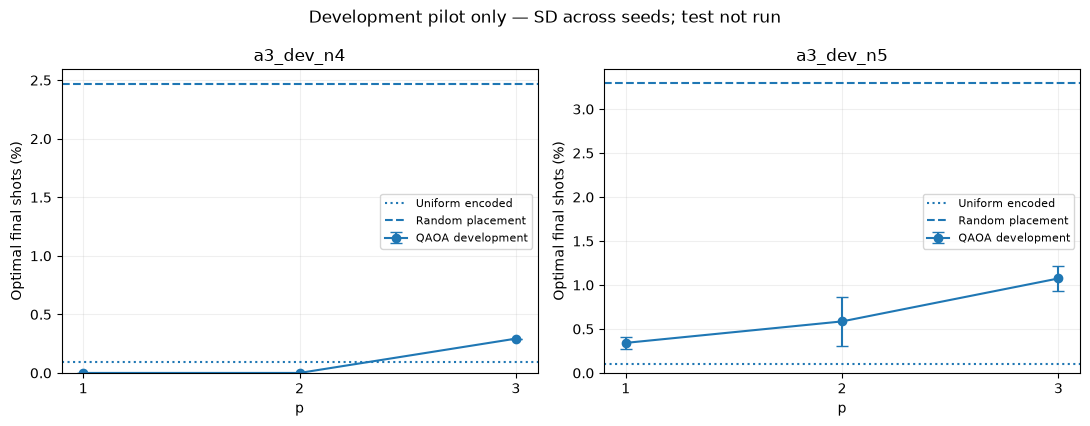

In [8]:
CAMPAIGN = json.loads((FOLDER / 'campaign.json').read_text(encoding='utf-8'))
verify_pilot(FOLDER, CAMPAIGN, CONTEXT)
ROWS = result_rows(FOLDER, CAMPAIGN, CONTEXT)
quality = pd.DataFrame(ROWS)
display(quality[['instance_id','role','p','seed','status','found_valid','found_optimal',
    'feasible_probability','optimal_probability','invalid_domain_probability',
    'optimal_lift_encoded','optimal_lift_structured_random','total_seconds','total_algorithm_shots']])
completed = quality[(quality['role']=='development') & (quality['status']=='completed')]
fig, axes = plt.subplots(1,2,figsize=(11,4.3))
for ax,name in zip(axes,['a3_dev_n4','a3_dev_n5']):
    part = completed[completed['instance_id']==name]
    if not part.empty:
        means = part.groupby('p')['optimal_probability'].mean()
        sd = part.groupby('p')['optimal_probability'].std().fillna(0)
        ax.errorbar(means.index,100*means,yerr=100*sd,marker='o',capsize=4,label='QAOA development')
    for method,label,style in [('uniform_encoded_domain_wall_y','Uniform encoded',':'),
                               ('random_assignment_y_inferred','Random placement','--')]:
        q = next(c['optimal_probability'] for c in CONTROLS if c['instance_id']==name and c['method']==method)
        ax.axhline(100*q,linestyle=style,label=label)
    ax.set(title=name,xlabel='p',ylabel='Optimal final shots (%)',xticks=[1,2,3])
    ax.set_ylim(bottom=0);ax.grid(alpha=.2);ax.legend(fontsize=8)
fig.suptitle('Development pilot only — SD across seeds; test not run')
fig.tight_layout();fig.savefig(FOLDER/'pilot_quality.png',dpi=150);plt.show()

## Bước9 — Xuất ZIP và checkpoint chi phí

Gửi ZIP dù partial. Save notebook rồi gửi kèm. Projection90trials dùng median
dev theo size/p và15test trials/group; chưa tính chi phí preparation của campaign
mới, khác cost structure hoặc failures. Không tự mở Notebook20 khi projection nhỏ.
Chỉ sau review pilot Windows mới khóa budget/phiên bản test. Bước này không đóng
Phase4 và không công bố lợi thế tốc độ.

In [9]:
ARCHIVE, ROWS, ASSESSMENT = export_pilot(FOLDER, CONTEXT)
print(json.dumps(ASSESSMENT, ensure_ascii=False, indent=2))
if ASSESSMENT['projected_90_trial_seconds'] is not None:
    print('Projection90trial:', round(ASSESSMENT['projected_90_trial_seconds']/3600,2), 'giờ; chưa phải dự báo bảo đảm.')
print('Gửi ZIP:', ARCHIVE)
print('Gửi kèm notebook19 sau Save. Giữ RESUME_DIR nếu pilot còn pending.')

{
  "status": "pilot_complete",
  "completed": 14,
  "planned": 14,
  "projected_90_trial_seconds": 15800.14822125001,
  "within_six_hours_by_projection": true,
  "projection_scope": "15 test trials per size/p times development median; excludes future preparation and failures; cost structure may differ; not a runtime guarantee",
  "depth_selection": "none",
  "test_campaign_started": false
}
Projection90trial: 4.39 giờ; chưa phải dự báo bảo đảm.
Gửi ZIP: C:\Users\Khiem\quang-tum-com-pu-ting\nt409-task-placement\data\reference_results\phase4k_three_host_pilot\pilot_20261012T073256184704Z\pilot_20261012T073256184704Z.zip
Gửi kèm notebook19 sau Save. Giữ RESUME_DIR nếu pilot còn pending.
